# Backend vs meal_response: CGMacros and Shanghai T2DM

This notebook contains executed results, not just code. It compares the backend's fixed XGBoost design with **both** meal_response model families, on **both** raw-data sources, individually and pooled. The Sharanya daily-forecast result appears separately because a daily average and a post-meal glucose curve are different prediction tasks.

The matched comparison uses identical eligible meals, held-out patients, labels and evaluation weights. The backend is adapted to these common inputs and endpoints; its original day-8 evaluation is **not** used to rank the pipelines. This experiment compares complete designs (features, fitting weights, tuning and target representation), so it cannot attribute a difference to one design choice alone.


In [1]:
from pathlib import Path
import sys, io, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "meal_response/training.py").exists())
sys.path.insert(0, str(root))
from meal_response.comparison_notebook import load_comparison, contributions, LABELS, ENDPOINTS, COMMON_TARGETS
from meal_response.training import predict_bundle
from meal_response.features import TARGETS, MINUTES
from backend.data import load_forecast_splits
import joblib
run = root / 'artifacts\\model_comparison\\20261010T143752048021Z'
examples, test, models, results, patient_scores, metrics = load_comparison(run)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
colors = {"Backend adapted": "#e07a36", "Meal response linear": "#6b69b2", "Meal response XGBoost": "#168b86", "Persistence": "#7c8790"}
def show(fig, name):
    fig.tight_layout()
    fig.savefig(run / (name + ".png"), dpi=160, bbox_inches="tight")
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=130, bbox_inches="tight")
    display(Image(data=buf.getvalue()))
    plt.close(fig)
display(Markdown("Artifacts: `" + str(run.relative_to(root)) + "`"))


Artifacts: `artifacts\model_comparison\20261010T143752048021Z`

## What is different?

| Design | Backend adapted | meal_response XGBoost | meal_response linear |
|---|---|---|---|
| Decision rule | Sum of 150 small regression trees per target | Sum of validation-selected regression trees at each horizon | Intercept plus a weighted sum of input features at each horizon |
| Inputs in this comparison | Meal macros, baseline, 30-minute slope, clock, seven-day glucose mean/std (11 available inputs in 13 slots) | Core meal macros, 13 recent glucose lags, trend/variability, history summaries and logged nutrition/coverage, with missingness indicators | Same core features as meal_response XGBoost |
| Outputs | Seven independently fitted endpoint/peak/rise/time targets | 24 independent glucose predictions at 5-minute intervals; endpoints and peak derived from the curve | Joint linear fit of 24 glucose outputs; derived endpoints |
| Training influence | Every meal has equal loss weight | Patient/source balancing × confidence factor × training-only large-rise emphasis | Same weighting as meal_response XGBoost |
| Selection | Fixed depth 3, 150 trees, learning rate .05, lambda 5 | 30 random trials, up to 2,000 trees, horizon-specific early stopping; validation selects parameters | Ordinary least squares; training-only imputation and scaling |
| Original protocol | Raw CGMacros: train calendar days 1–7, test day 8 for known people. Sharanya: supplied patient splits. | Held-out patients, with source/cohort stratification | Same held-out patients |

**Adaptations made for the matched experiment:** backend inputs come from the same causal core table as meal_response. The slope is `(lag_0 - lag_30) / 30`; history std uses the core population std. HR and activity are unavailable in core and remain missing for both sources. Backend peak is trained over minutes 5–120 (rather than including minute zero), matching meal_response. The original backend's calendar-day split is replaced with meal_response's patient manifest. These changes make this an explicitly adapted backend comparison, not a rerun of its original protocol.

Source-only models learn from their own source; pooled models learn from both sources. Validation and test remain disjoint from training. IDs, source/cohort labels, confidence and future values are not prediction features. Confidence and observed training rises only affect training weights.


## Dataset coverage and verification
Saved pooled models were checked against current raw-data fingerprints, reconstructed features, saved predictions, weighting and online inference before reuse. Source-only meal_response models were freshly trained with the default full tuning budget.

In [2]:
coverage = examples.groupby(["source", "partition"]).agg(patients=("participant", "nunique"), meals=("meal_id", "size"))
display(coverage)
display(pd.DataFrame(json.loads((run / "provenance.json").read_text())["verified_models"]))
display(Markdown("**Label limits:** T2DM supplied outcomes include interpolation; CGMacros original-observation flags are unavailable. Accuracy here is against the supplied curves, not independently observed five-minute measurements. The original test set has already been inspected in earlier experiments; treat this comparison as exploratory."))


patients  meals
source    partition                  
cg_macros test               6    152
          train             33   1060
          validation         6    186
t2dm      test               9     90
          train             44    356
          validation         9     57

,dataset,model,features,test_meals,saved_predictions_match,online_prediction_matches,outcomes_match,current_examples_match,confidence_and_rise_weights_match
0,combined,linear,core,242,True,True,True,True,True
1,combined,xgboost,core,242,True,True,True,True,True


**Label limits:** T2DM supplied outcomes include interpolation; CGMacros original-observation flags are unavailable. Accuracy here is against the supplied curves, not independently observed five-minute measurements. The original test set has already been inspected in earlier experiments; treat this comparison as exploratory.

## Fitted model settings and full-curve results
The meal_response curve RMSE averages each patient's 24-point curve RMSE. Backend predicts discrete endpoints and has no full-curve RMSE. The source breakdowns below use exactly the same test meals as the endpoint comparison. Do not compare a 24-point curve RMSE directly with an endpoint MAE.

In [3]:
configuration_rows, curve_rows = [], []
for mode in ["cg_macros", "t2dm", "combined"]:
    for family in ["linear", "xgboost"]:
        report = json.loads((run / f"{mode}_{family}_core/metrics.json").read_text())
        configuration_rows.append({"training_data": mode, "model": LABELS[family], **report["configuration"], "trials": len(report["trials"]), "validation_curve_RMSE": report["validation_patient_curve_rmse"]})
        sources = ["cg_macros", "t2dm"] if mode == "combined" else [mode]
        for source in sources:
            item = report["test"][f"source:{source}"]
            error = item["metrics"]["curve"]
            curve_rows.append({"training_data": mode, "source": source, "model": LABELS[family], "patients": item["patients"], "meals": item["meals"], "curve_RMSE": error["rmse"], "95% interval": error["ci95"]["rmse"], "persistence_curve_RMSE": report["persistence"][f"source:{source}"]["metrics"]["curve"]["rmse"]})
display(pd.DataFrame(configuration_rows))
display(pd.DataFrame(curve_rows).round(2))
pd.DataFrame(curve_rows).to_csv(run / "full_curve_metrics.csv", index=False)


,training_data,model,estimator,rank,transformed_features,trials,validation_curve_RMSE,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda
0,cg_macros,Meal response linear,ordinary_least_squares,59.0,84.0,0,36.663453,NaN,NaN,NaN,NaN,NaN,NaN
1,cg_macros,Meal response XGBoost,NaN,NaN,NaN,30,32.222465,2.0,0.071988,0.725333,0.824742,6.0,1.374528
2,t2dm,Meal response linear,ordinary_least_squares,56.0,86.0,0,31.196198,NaN,NaN,NaN,NaN,NaN,NaN
3,t2dm,Meal response XGBoost,NaN,NaN,NaN,30,34.385746,2.0,0.071988,0.725333,0.824742,6.0,1.374528
4,combined,Meal response linear,ordinary_least_squares,71.0,86.0,0,33.296424,NaN,NaN,NaN,NaN,NaN,NaN
5,combined,Meal response XGBoost,NaN,NaN,NaN,30,32.594931,2.0,0.046389,0.743357,0.731021,5.0,6.288801


,training_data,source,model,patients,meals,curve_RMSE,95% interval,persistence_curve_RMSE
0,cg_macros,cg_macros,Meal response linear,6,152,185.24,"[35.11658149412016, 391.9126494573256]",37.62
1,cg_macros,cg_macros,Meal response XGBoost,6,152,28.15,"[21.55758562028738, 35.509323997196574]",37.62
2,t2dm,t2dm,Meal response linear,9,90,35.58,"[32.523964265829505, 38.69064350664089]",35.69
3,t2dm,t2dm,Meal response XGBoost,9,90,32.78,"[28.68603283001231, 36.689734426861676]",35.69
4,combined,cg_macros,Meal response linear,6,152,35.77,"[30.211468038791907, 42.63590991541781]",37.62
5,combined,t2dm,Meal response linear,9,90,33.44,"[30.224721511750626, 36.72831467957631]",35.69
6,combined,cg_macros,Meal response XGBoost,6,152,28.05,"[21.952142152131, 34.942108677741]",37.62
7,combined,t2dm,Meal response XGBoost,9,90,33.50,"[29.456508792703854, 38.044305069478355]",35.69


## Matched results: the same 30/60/90/120-minute targets
All errors below give each held-out patient equal weight within a source. MAE/RMSE for glucose and peak/rise are in mg/dL; time-to-peak error is in minutes. Lower is better. The daily-mean MAE is deliberately excluded from these rankings.

model                                Backend adapted  ...  Persistence
training_data source    target                        ...             
cg_macros     cg_macros glucose_120            23.05  ...        31.86
                        glucose_30             20.44  ...        22.91
                        glucose_60             24.18  ...        32.76
                        glucose_90             26.96  ...        35.17
combined      cg_macros glucose_120            23.12  ...        31.86
                        glucose_30             19.94  ...        22.91
                        glucose_60             23.07  ...        32.76
                        glucose_90             27.06  ...        35.17
              t2dm      glucose_120            33.61  ...        40.45
                        glucose_30             18.17  ...        15.62
                        glucose_60             30.15  ...        30.22
                        glucose_90             32.58  ...        38.41
t2dm          t2dm      glucose_120            33.05  ...        40.45
                        glucose_30             17.79  ...        15.62
                        glucose_60             27.51  ...        30.22
                        glucose_90             31.98  ...        38.41

[16 rows x 4 columns]

Endpoint RMSE (mg/dL)                Backend adapted  ...  Persistence
training_data source    target                        ...             
cg_macros     cg_macros glucose_120            30.56  ...        43.18
                        glucose_30             26.88  ...        31.10
                        glucose_60             31.01  ...        42.28
                        glucose_90             34.76  ...        47.28
combined      cg_macros glucose_120            30.58  ...        43.18
                        glucose_30             25.92  ...        31.10
                        glucose_60             30.36  ...        42.28
                        glucose_90             34.75  ...        47.28
              t2dm      glucose_120            43.95  ...        54.44
                        glucose_30             23.71  ...        21.29
                        glucose_60             36.03  ...        38.27
                        glucose_90             39.68  ...        48.46
t2dm          t2dm      glucose_120            43.00  ...        54.44
                        glucose_30             22.29  ...        21.29
                        glucose_60             33.14  ...        38.27
                        glucose_90             39.67  ...        48.46

[16 rows x 4 columns]

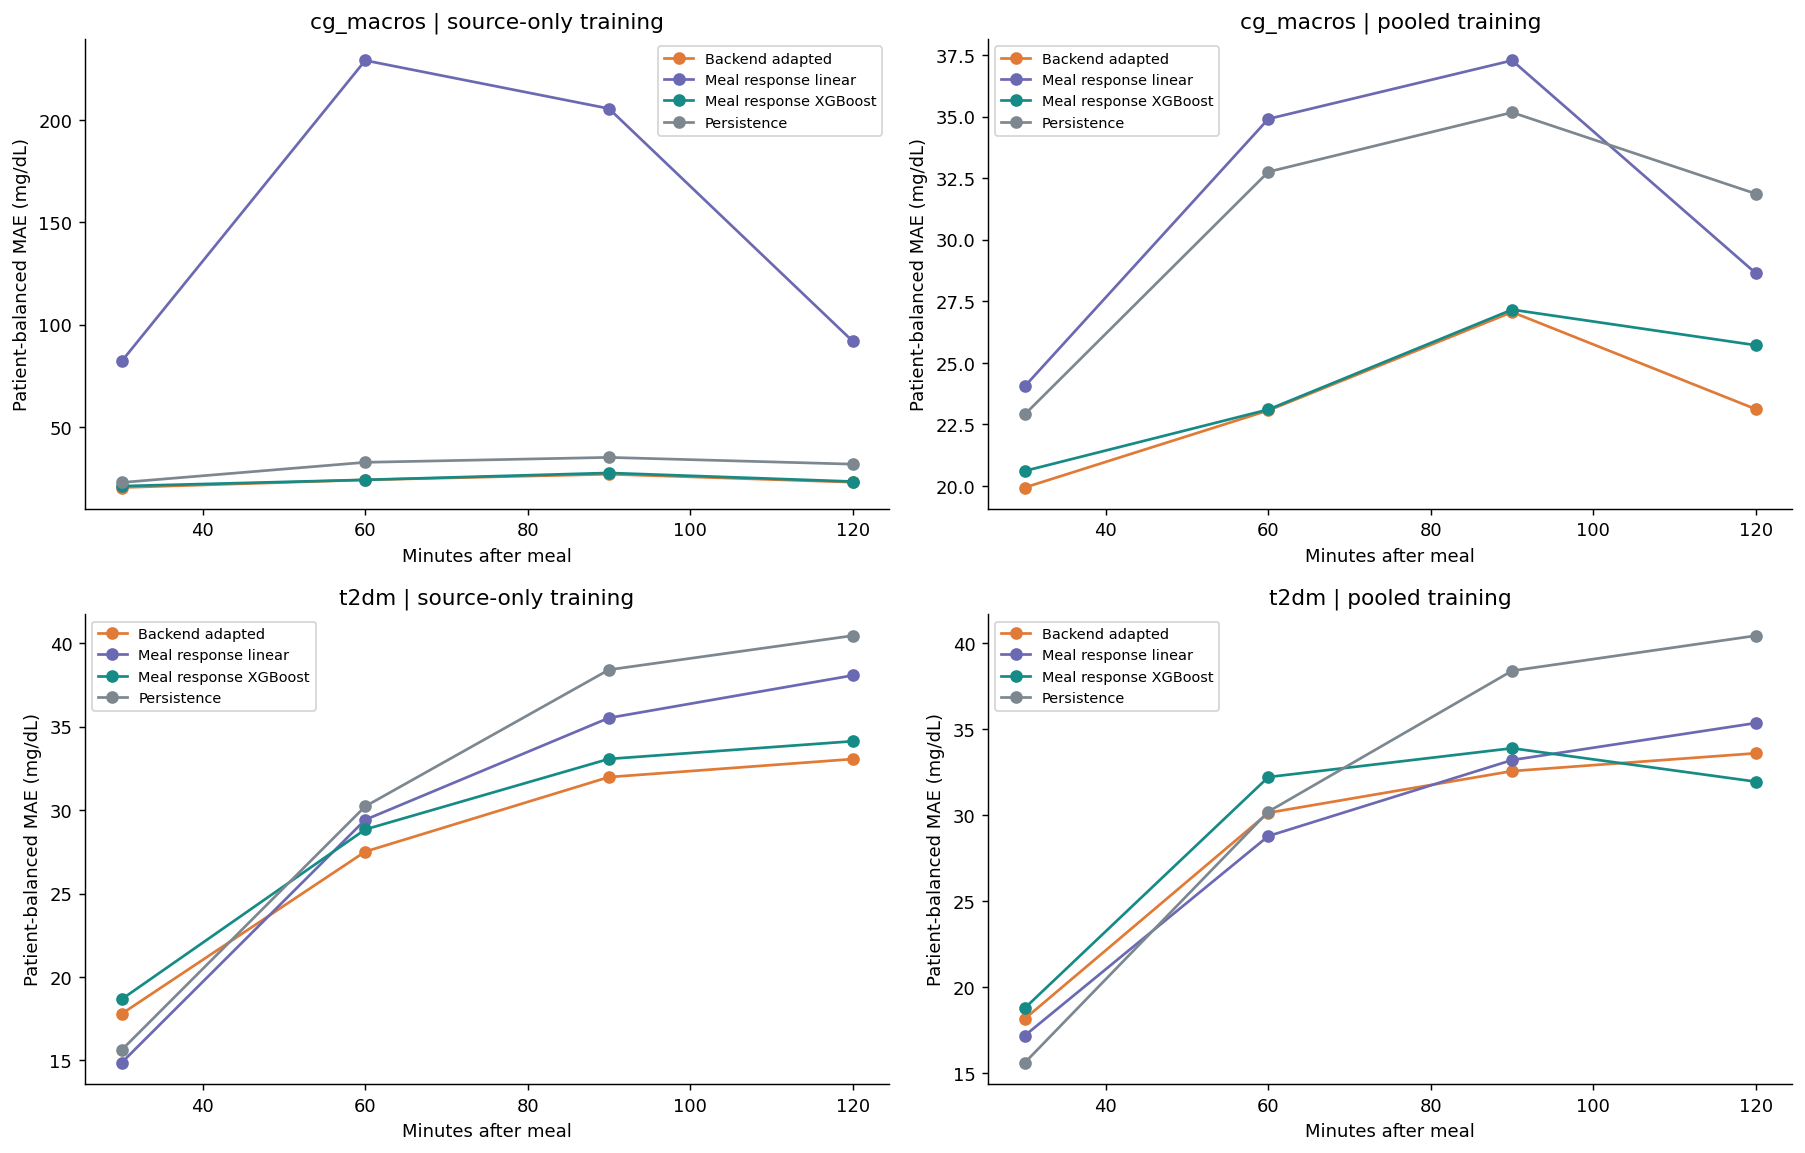

model                                 Backend adapted  ...  Persistence
training_data source    target                         ...             
cg_macros     cg_macros peak                    25.01  ...        49.22
                        peak_rise               24.81  ...        49.22
                        time_to_peak            28.41  ...        61.88
combined      cg_macros peak                    24.68  ...        49.22
                        peak_rise               25.86  ...        49.22
                        time_to_peak            29.01  ...        61.88
              t2dm      peak                    28.80  ...        35.36
                        peak_rise               29.18  ...        35.36
                        time_to_peak            32.85  ...        63.98
t2dm          t2dm      peak                    29.65  ...        35.36
                        peak_rise               27.42  ...        35.36
                        time_to_peak            28.43  ...        63.98

[12 rows x 4 columns]

**Internal consistency:** percentage of pooled test predictions with incompatible endpoints. Separate backend regressors can disagree; curve-derived peak and rise share a common construction.

,source,model,peak_below_predicted_endpoint_pct,inconsistent_peak_rise_pct
0,cg_macros,Backend adapted,0.66,100.0
1,cg_macros,Meal response linear,0.00,0.0
2,cg_macros,Meal response XGBoost,0.00,0.0
3,t2dm,Backend adapted,2.22,100.0
4,t2dm,Meal response linear,0.00,0.0
5,t2dm,Meal response XGBoost,0.00,0.0


In [4]:
endpoint_table = metrics.loc[metrics.target.isin(ENDPOINTS)].pivot(index=["training_data", "source", "target"], columns="model", values="mae")
display(endpoint_table.round(2))
display(metrics.loc[metrics.target.isin(ENDPOINTS)].pivot(index=["training_data", "source", "target"], columns="model", values="rmse").round(2).rename_axis(columns="Endpoint RMSE (mg/dL)"))
metrics.to_csv(run / "matched_metrics.csv", index=False)
results.to_csv(run / "matched_predictions.csv", index=False)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, source in enumerate(["cg_macros", "t2dm"]):
    for col, mode in enumerate([source, "combined"]):
        ax = axes[row, col]
        block = metrics.loc[(metrics.source == source) & (metrics.training_data == mode) & metrics.target.isin(ENDPOINTS)]
        for label in colors:
            values = block.loc[block.model == label].set_index("target").reindex(ENDPOINTS)
            ax.plot([30, 60, 90, 120], values.mae, marker="o", color=colors[label], label=label)
        ax.set(title=f"{source} | {'source-only training' if col == 0 else 'pooled training'}", xlabel="Minutes after meal", ylabel="Patient-balanced MAE (mg/dL)")
        ax.legend(fontsize=8)
show(fig, "endpoint_errors")
display(metrics.loc[~metrics.target.isin(ENDPOINTS)].pivot(index=["training_data", "source", "target"], columns="model", values="mae").round(2))
consistency_rows = []
for source in ["cg_macros", "t2dm"]:
    for family in ["backend", "linear", "xgboost"]:
        p = results.loc[(results.source == source) & (results.training_data == "combined") & (results.family == family)].pivot(index="meal_id", columns="target", values="prediction")
        base = test.set_index("meal_id").baseline.reindex(p.index)
        consistency_rows.append({"source":source, "model":LABELS[family], "peak_below_predicted_endpoint_pct":100 * (p.peak < p[ENDPOINTS].max(axis=1) - .001).mean(), "inconsistent_peak_rise_pct":100 * (np.abs(p.peak - base - p.peak_rise) > .001).mean()})
display(Markdown("**Internal consistency:** percentage of pooled test predictions with incompatible endpoints. Separate backend regressors can disagree; curve-derived peak and rise share a common construction."))
display(pd.DataFrame(consistency_rows).round(2))


## Does an apparent improvement hold across patients?
Paired patient bootstrap: the 60-minute MAE difference is `meal_response − backend`. Negative values favor meal_response. Each resample uses the same patients for both models. Intervals describe patient variation on this inspected test set, not a fresh confirmatory evaluation.

In [5]:
rng = np.random.default_rng(42)
paired_rows = []
for source in ["cg_macros", "t2dm"]:
    for mode in [source, "combined"]:
        p = patient_scores.loc[(patient_scores.source == source) & (patient_scores.training_data == mode) & (patient_scores.target == "glucose_60")].pivot(index="participant", columns="model", values="mae")
        for label in [LABELS["linear"], LABELS["xgboost"]]:
            delta = (p[label] - p[LABELS["backend"]]).to_numpy()
            draws = rng.choice(delta, size=(2000, len(delta)), replace=True).mean(axis=1)
            lo, hi = np.quantile(draws, [.025, .975])
            paired_rows.append({"source": source, "training_data": mode, "comparison": label, "patients": len(delta), "MAE difference": delta.mean(), "95% lower": lo, "95% upper": hi})
paired = pd.DataFrame(paired_rows)
display(paired.round(2))
paired.to_csv(run / "paired_patient_bootstrap.csv", index=False)


,source,training_data,comparison,patients,MAE difference,95% lower,95% upper
0,cg_macros,cg_macros,Meal response linear,6,204.91,5.96,499.70
1,cg_macros,cg_macros,Meal response XGBoost,6,0.03,-2.23,2.48
2,cg_macros,combined,Meal response linear,6,11.83,1.31,23.30
3,cg_macros,combined,Meal response XGBoost,6,0.04,-1.22,1.69
4,t2dm,t2dm,Meal response linear,9,1.91,-3.20,6.20
5,t2dm,t2dm,Meal response XGBoost,9,1.33,-1.60,4.61
6,t2dm,combined,Meal response linear,9,-1.35,-7.07,4.62
7,t2dm,combined,Meal response XGBoost,9,2.08,-0.33,4.82


## Why the CGMacros source-only linear result is unusually poor

This result is retained as measured. Ordinary least squares has no coefficient shrinkage and no bound on its output. The diagnostics below show the fitted matrix rank, coefficient magnitude and worst held-out predictions. Rank deficiency indicates redundant inputs; it alone does not prove the cause of bad generalization. Large coefficients and extreme predictions here are consistent with an unstable linear extrapolation using correlated inputs. Pooled linear regression is a different fitted model and does not show the same magnitude of failure. Ridge regularization would be a separate experiment and has not been substituted into these results.


In [6]:
diagnostics = []
for mode in ["cg_macros", "t2dm", "combined"]:
    estimator = models[(mode, "linear")]["models"]
    diagnostics.append({"training_data":mode, "transformed_features":estimator.coef_.shape[1], "matrix_rank":estimator.rank_, "largest_absolute_coefficient":np.abs(estimator.coef_).max()})
display(pd.DataFrame(diagnostics).round(2))
bad = results.loc[(results.training_data == "cg_macros") & (results.family == "linear") & (results.target == "glucose_60")].nlargest(5, "absolute_error")
display(bad[["participant", "meal_id", "truth", "prediction", "absolute_error"]].round(2))
frame = test.loc[test.source == "cg_macros"]
values, reference, prediction = contributions(models[("cg_macros", "linear")], "linear", frame)
index = test.loc[test.meal_id == bad.iloc[0].meal_id].index[0]
local = values.loc[index]
top = local.loc[local.abs().nlargest(8).index]
display(top.rename("signed contribution to worst 60-minute prediction (mg/dL)").to_frame().round(2))


,training_data,transformed_features,matrix_rank,largest_absolute_coefficient
0,cg_macros,84,59,947.49
1,t2dm,86,56,119.41
2,combined,86,71,75.30


,participant,meal_id,truth,prediction,absolute_error
1093,cg_macros:007,CGMacros-007|2023-11-10 12:24:00,106.4,1438.94,1332.54
1086,cg_macros:007,CGMacros-007|2023-11-09 18:30:00,129.2,1360.14,1230.94
1079,cg_macros:007,CGMacros-007|2023-11-08 08:47:00,135.6,1029.56,893.96
1072,cg_macros:007,CGMacros-007|2023-11-07 12:18:00,109.0,844.74,735.74
1912,cg_macros:026,CGMacros-026|2021-04-02 10:01:00,118.0,840.84,722.84


,signed contribution to worst 60-minute prediction (mg/dL)
history_days,1010.48
history_7d_coverage,298.17
history_3d_mean,-30.33
lag_10,29.89
lag_35,18.62
history_7d_std,-15.87
protein,-15.50
history_1d_mean,14.21


## The same held-out meals, side by side
For each source, show a typical and a difficult meal, selected by the pooled XGBoost's median and worst 60-minute absolute error. These are illustrative examples, not independent evidence. Backend dots show its four endpoint predictions; it has no fitted full curve.

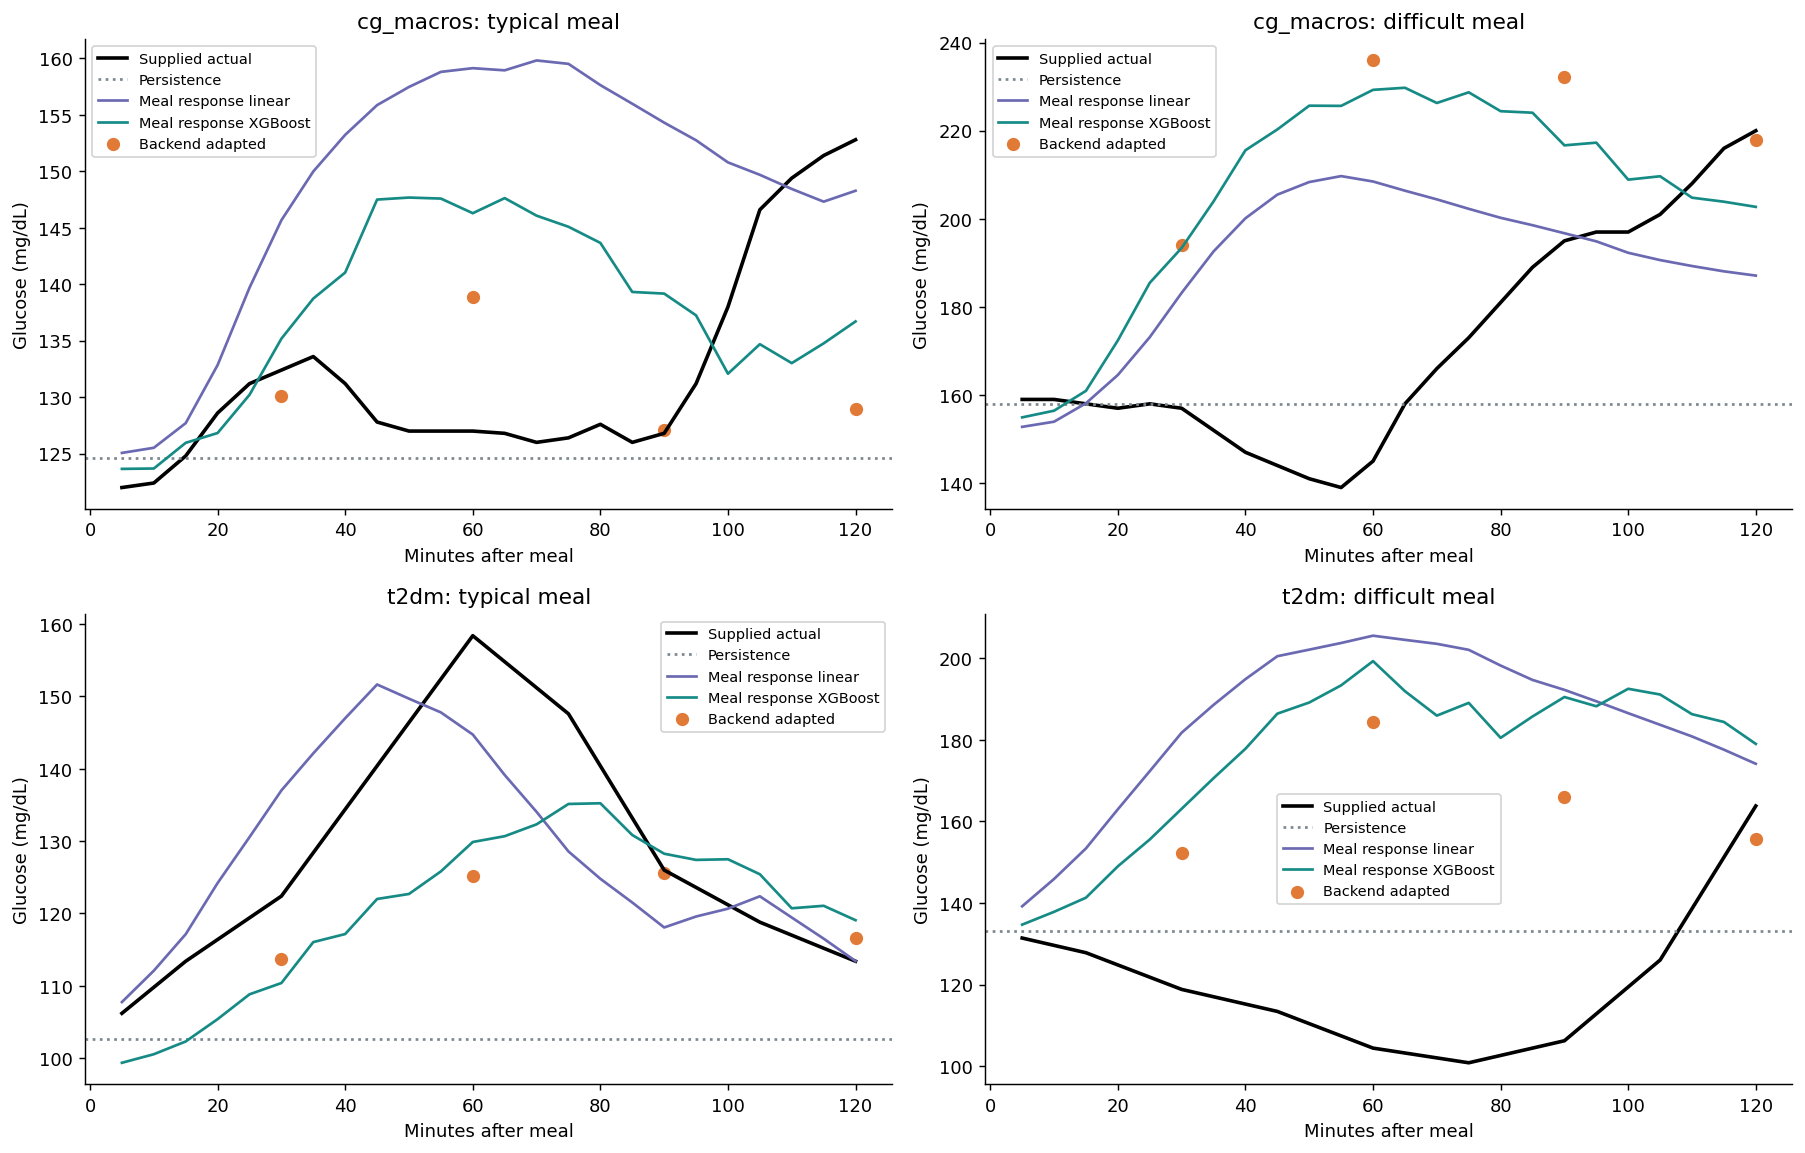

,source,participant,time,meal_id,carbs,protein,fat,calories,baseline
42,cg_macros,cg_macros:018,2024-02-08 13:22:00,CGMacros-018|2024-02-08 13:22:00,16.00,66.00,14.0,435.0,124.6
207,t2dm,t2dm:2080,2021-08-17 06:20:00,2080_0_20210816_20210817T0620,44.94,28.98,25.6,516.1,102.6


In [7]:
chosen = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for r, source in enumerate(["cg_macros", "t2dm"]):
    block = results.loc[(results.source == source) & (results.training_data == "combined") & (results.family == "xgboost") & (results.target == "glucose_60")].sort_values("absolute_error")
    ids = [block.iloc[len(block)//2].meal_id, block.iloc[-1].meal_id]
    chosen[source] = ids[0]
    for c, meal_id in enumerate(ids):
        row = test.loc[test.meal_id == meal_id]
        ax = axes[r, c]
        ax.plot(MINUTES, row[TARGETS].to_numpy()[0], color="black", lw=2, label="Supplied actual")
        ax.axhline(row.baseline.iloc[0], color=colors["Persistence"], ls=":", label="Persistence")
        for family in ["linear", "xgboost"]:
            ax.plot(MINUTES, predict_bundle(models[("combined", family)], row)[0], color=colors[LABELS[family]], label=LABELS[family])
        b = results.loc[(results.training_data == "combined") & (results.family == "backend") & (results.meal_id == meal_id)].set_index("target")
        ax.scatter([30,60,90,120], b.loc[ENDPOINTS].prediction, color=colors[LABELS["backend"]], s=40, label=LABELS["backend"])
        ax.set(title=f"{source}: {'typical' if c == 0 else 'difficult'} meal", xlabel="Minutes after meal", ylabel="Glucose (mg/dL)")
        ax.legend(fontsize=8)
show(fig, "same_meal_predictions")
display(test.loc[test.meal_id.isin(sum(([v] for v in chosen.values()), [])), ["source", "participant", "time", "meal_id", "carbs", "protein", "fat", "calories", "baseline"]])


## How are they making decisions?
Trees repeatedly split on feature thresholds. Each leaf contributes a correction and the model adds those corrections. Linear regression adds `coefficient × transformed feature value` to its intercept, with no tree thresholds or learned interactions.

The plots explain the **60-minute prediction** of the pooled models. Tree models use exact native TreeSHAP, limited to the trees actually used by early stopping. The linear model uses exact contributions relative to the zero point after training-fitted scaling. Those reference points differ, so importance magnitudes across families are descriptive, not causal comparisons. All contribution sums are checked against model predictions.

Mean absolute contributions show which inputs a model uses most on held-out rows. Correlated glucose lags/history summaries may share or shift attribution; missingness indicators can also influence the prediction. These are explanations of model behavior, not physiological effects.

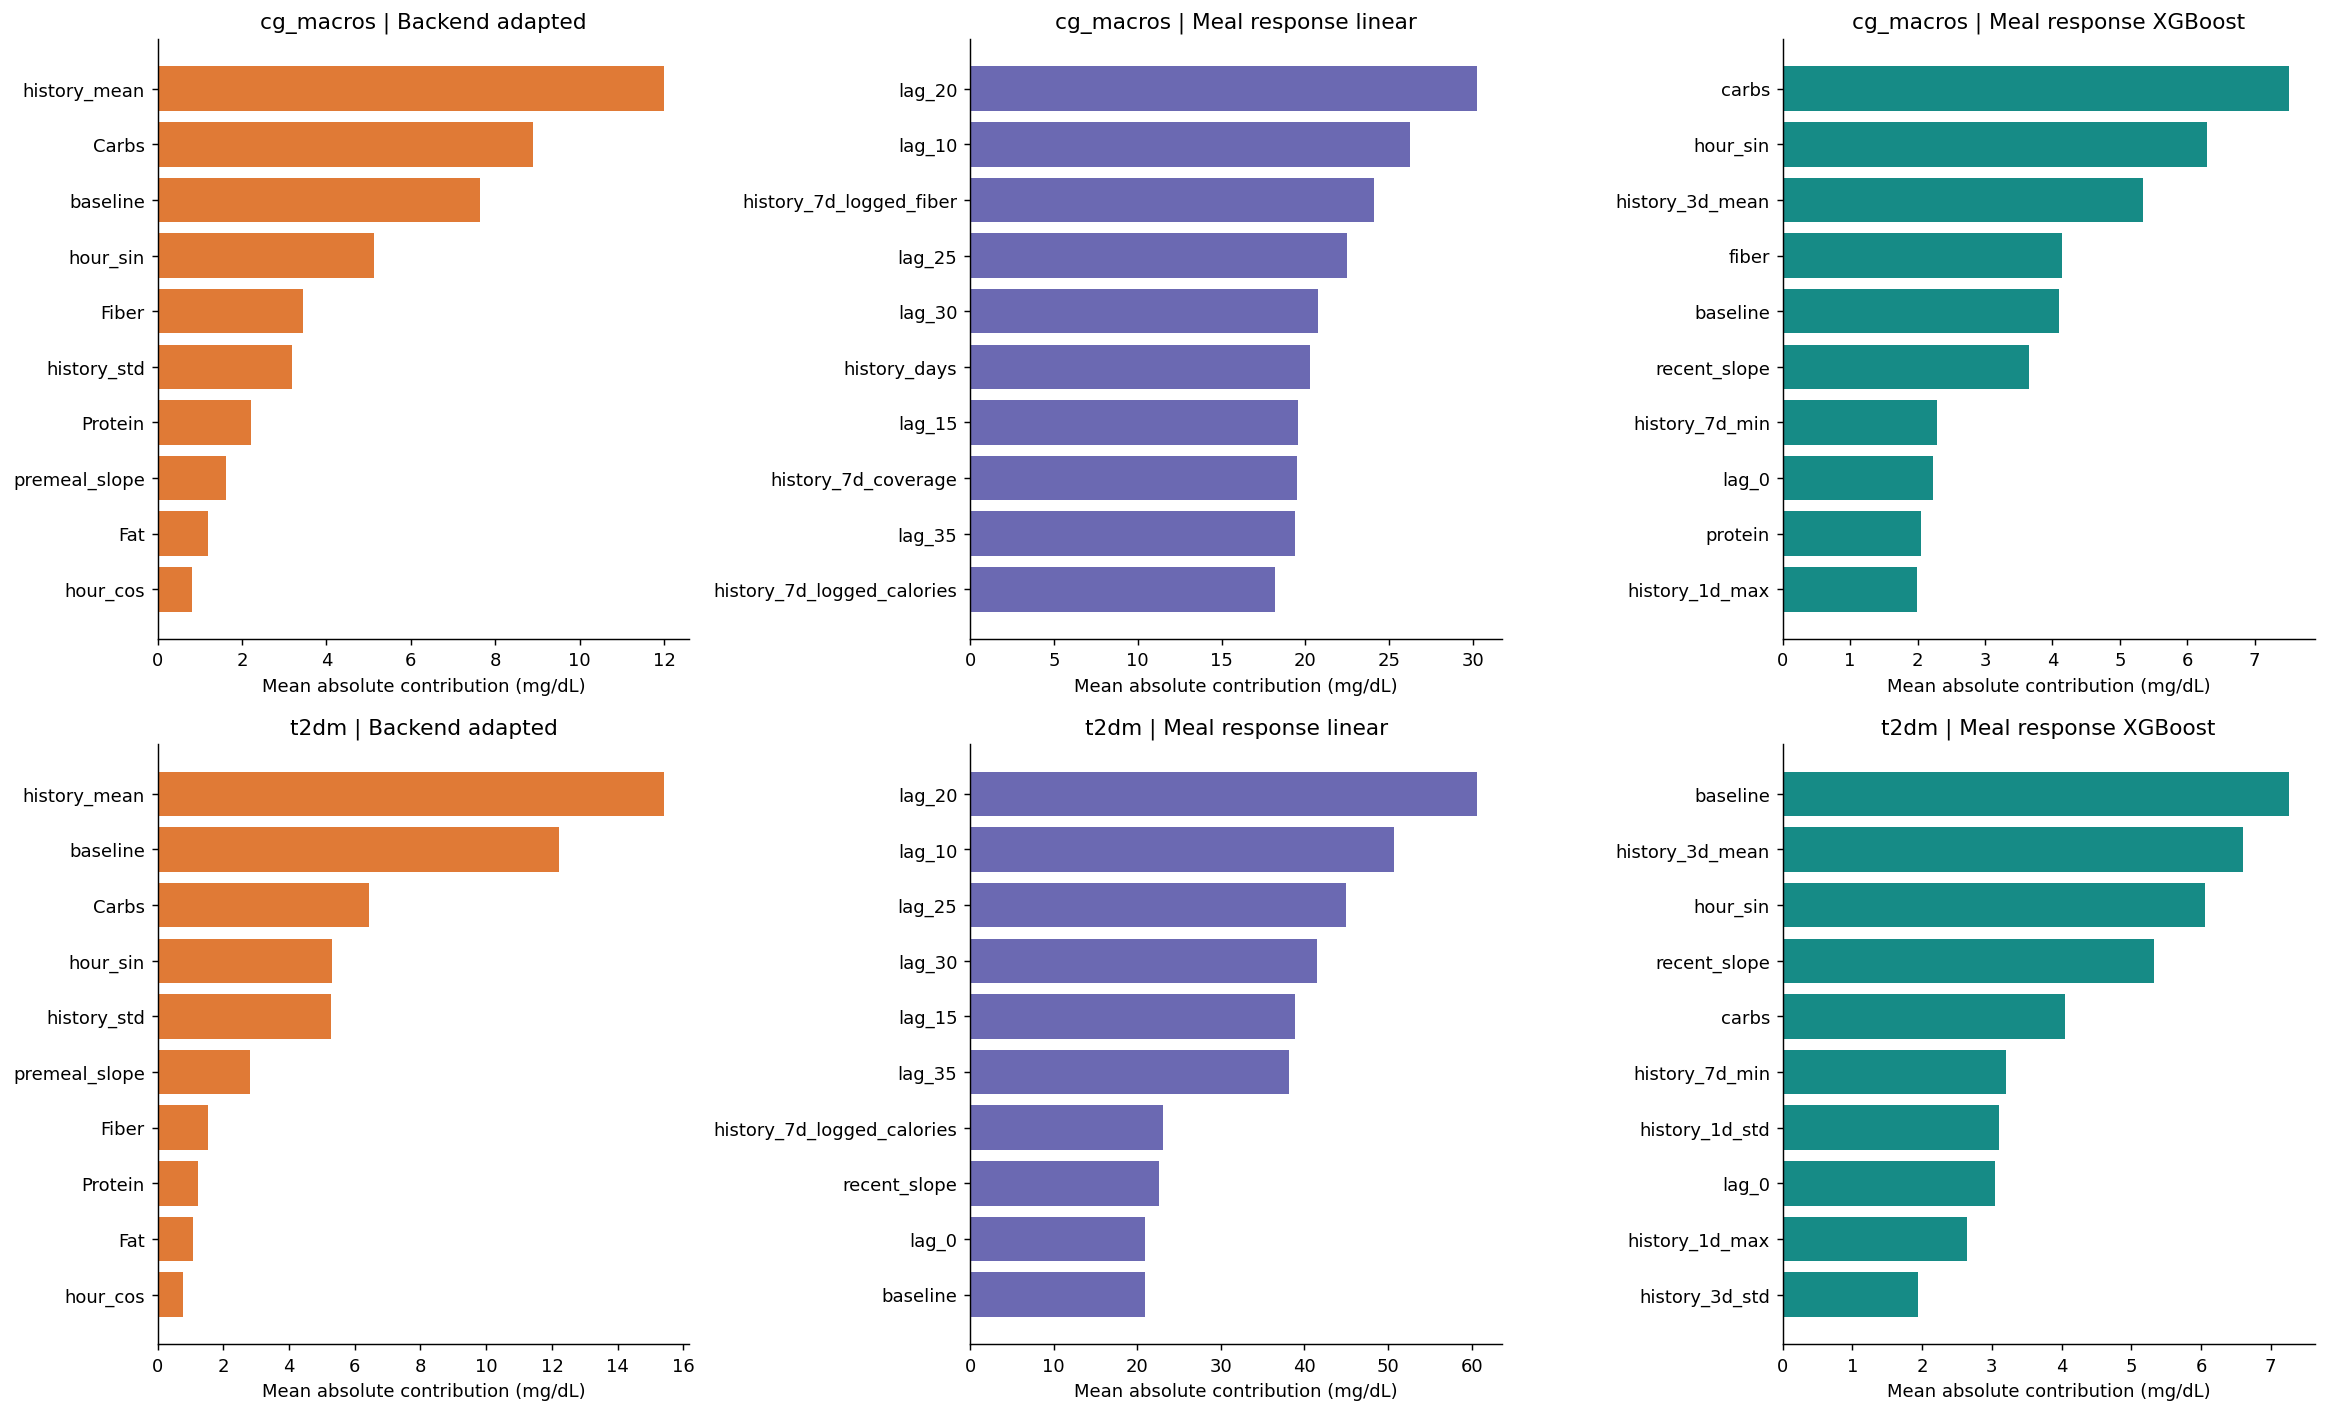

In [8]:
explanations = {}
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
importance_rows = []
for r, source in enumerate(["cg_macros", "t2dm"]):
    frame = test.loc[test.source == source]
    for c, family in enumerate(["backend", "linear", "xgboost"]):
        values, reference, prediction = contributions(models[("combined", family)], family, frame)
        explanations[(source, family)] = (values, reference, prediction)
        importance = values.abs().mean().sort_values(ascending=False)
        for name, value in importance.items():
            importance_rows.append({"source":source, "model":LABELS[family], "feature":name, "mean_abs_contribution":value})
        top = importance.head(10).sort_values()
        axes[r,c].barh(top.index, top.values, color=colors[LABELS[family]])
        axes[r,c].set(title=f"{source} | {LABELS[family]}", xlabel="Mean absolute contribution (mg/dL)")
show(fig, "global_decision_features")
pd.DataFrame(importance_rows).to_csv(run / "feature_contributions_60min.csv", index=False)


## Why this individual prediction went up or down
Positive contributions push the prediction above the model reference; negative contributions lower it. Each panel uses the same typical held-out meal for that source. The displayed top ten features plus the remaining-feature total reconstruct the prediction.

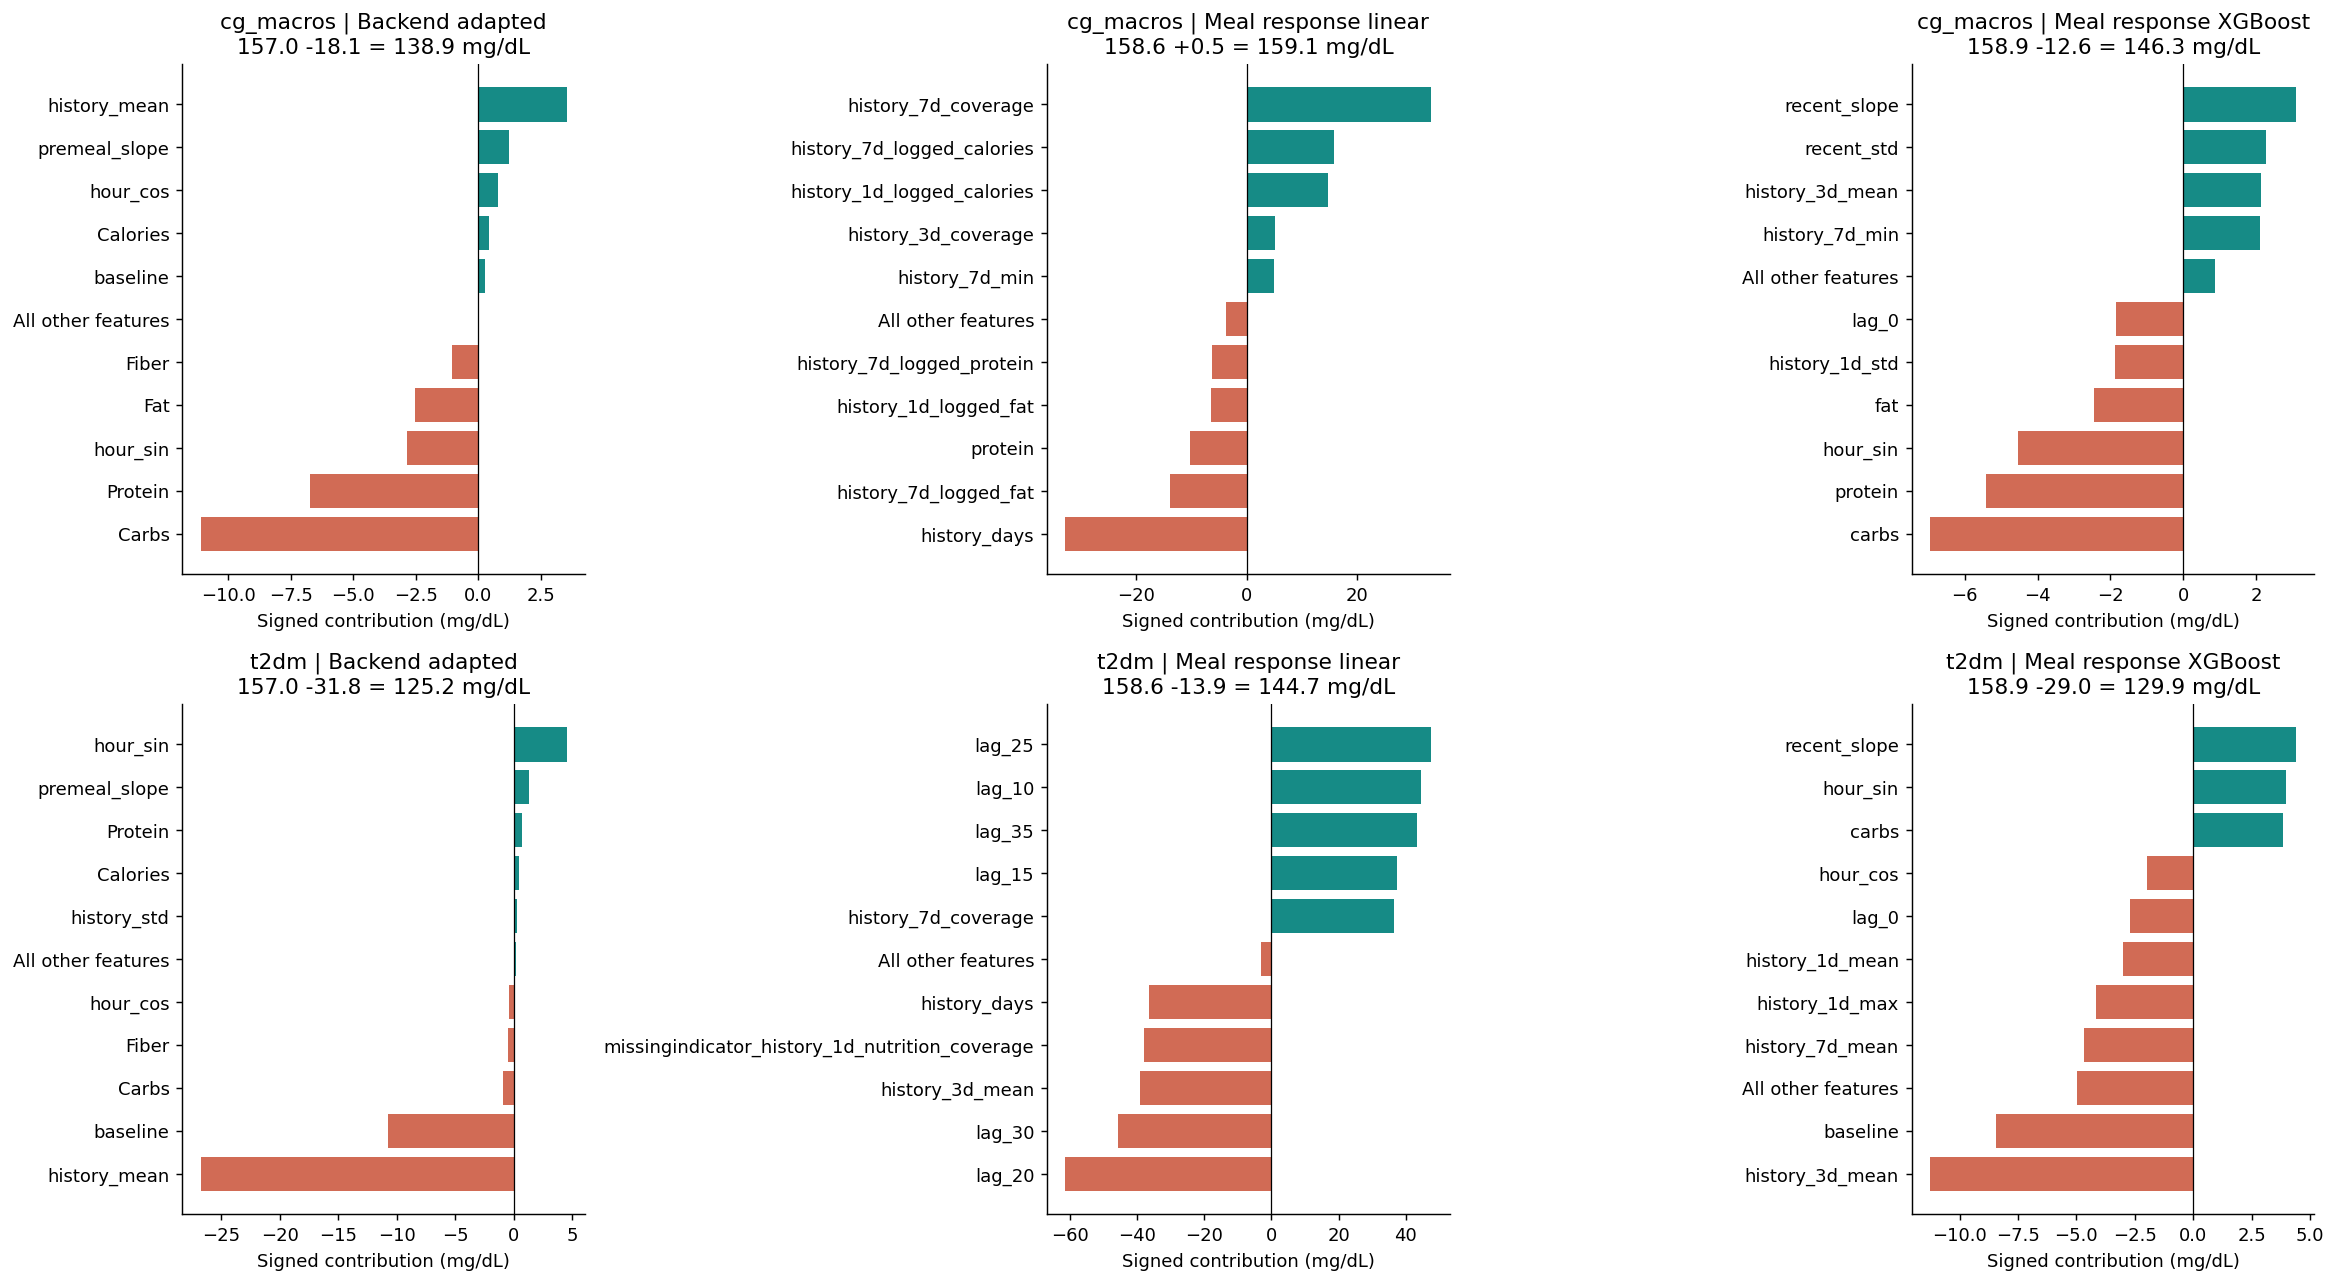

,source,model,reference,feature_sum,prediction,actual_glucose_60
0,cg_macros,Backend adapted,156.98,-18.08,138.90,127.0
1,cg_macros,Meal response linear,158.63,0.50,159.14,127.0
2,cg_macros,Meal response XGBoost,158.86,-12.57,146.29,127.0
3,t2dm,Backend adapted,156.98,-31.81,125.17,158.4
4,t2dm,Meal response linear,158.63,-13.90,144.74,158.4
5,t2dm,Meal response XGBoost,158.86,-28.98,129.88,158.4


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
local_rows = []
for r, source in enumerate(["cg_macros", "t2dm"]):
    index = test.loc[test.meal_id == chosen[source]].index[0]
    for c, family in enumerate(["backend", "linear", "xgboost"]):
        values, reference, prediction = explanations[(source,family)]
        position = values.index.get_loc(index)
        full = values.loc[index]
        top = full.loc[full.abs().nlargest(10).index].copy()
        top.loc["All other features"] = full.sum() - top.sum()
        top = top.sort_values()
        axes[r,c].barh(top.index, top.values, color=["#d16b55" if v < 0 else "#168b86" for v in top.values])
        axes[r,c].axvline(0, color="black", lw=.7)
        axes[r,c].set(title=f"{source} | {LABELS[family]}\n{reference[position]:.1f} {full.sum():+.1f} = {prediction[position]:.1f} mg/dL", xlabel="Signed contribution (mg/dL)")
        local_rows.append({"source":source, "model":LABELS[family], "reference":reference[position], "feature_sum":full.sum(), "prediction":prediction[position], "actual_glucose_60":test.loc[index,"glucose_60"]})
show(fig, "individual_decisions")
display(pd.DataFrame(local_rows).round(2))


## The Sharanya daily-mean model, separately
This is the backend model from the preceding task. It uses 28 daily glucose summaries plus history food/medication/logging features to predict `target` (daily mean glucose). Its fixed XGBoost settings resemble the backend meal regressors, but its target and inputs differ. A lower daily-average MAE cannot establish that it is a better meal-response model. The prepared CSVs' historical `predicted_glucose_mean` and `absolute_error` columns are excluded from fitting; their original algorithm is not identified here.

,split,model,rows,row_MAE,row_RMSE,patient_MAE,patient_RMSE
0,validation,Backend daily XGBoost,74,12.07,17.34,12.08,16.29
1,validation,Last-day mean baseline,74,12.44,17.95,12.10,16.91
2,test,Backend daily XGBoost,65,12.23,17.83,13.51,19.32
3,test,Last-day mean baseline,65,10.32,15.13,12.05,18.02


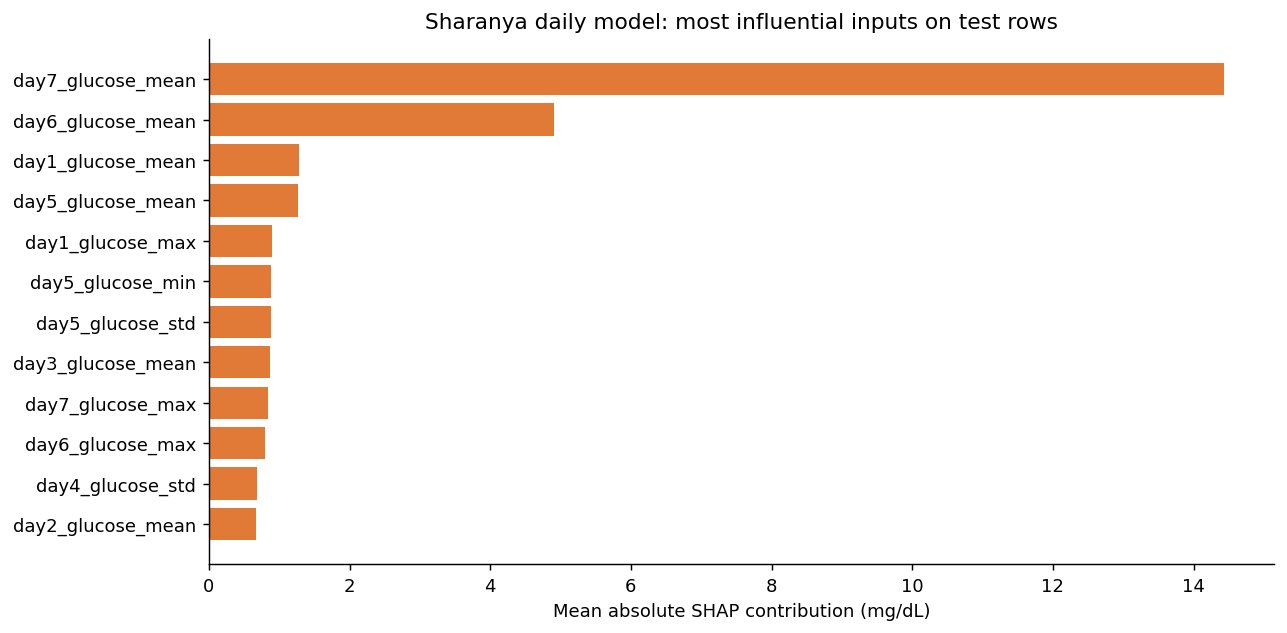

In [10]:
splits, daily_features = load_forecast_splits(run / "daily_snapshot")
daily_bundle = joblib.load(run / "daily_snapshot/regression.joblib")
assert daily_bundle.get("dataset") == "daily_forecast", "Run python -m backend.model on Sharanya first"
daily_rows = []
for split in ["validation", "test"]:
    frame = splits[split]
    pred = daily_bundle["model"].predict(frame[daily_bundle["features"]])
    for label, values in [("Backend daily XGBoost", pred), ("Last-day mean baseline", frame.day7_glucose_mean.to_numpy())]:
        err = values - frame.target.to_numpy()
        per_patient = pd.DataFrame({"Patient":frame.Patient, "abs":np.abs(err), "sq":err**2}).groupby("Patient").mean()
        daily_rows.append({"split":split, "model":label, "rows":len(frame), "row_MAE":np.abs(err).mean(), "row_RMSE":np.sqrt((err**2).mean()), "patient_MAE":per_patient["abs"].mean(), "patient_RMSE":np.sqrt(per_patient["sq"].mean())})
display(pd.DataFrame(daily_rows).round(2))
frame = splits["test"]
pipeline = daily_bundle["model"]
from backend.explain import tree_contributions
daily_x = pipeline.steps[0][1].transform(frame[daily_bundle["features"]])
daily_importance = pd.Series(np.abs(tree_contributions(pipeline.steps[1][1], daily_x)).mean(axis=0), index=daily_bundle["features"]).nlargest(12).sort_values()
fig, ax = plt.subplots(figsize=(10,5))
ax.barh(daily_importance.index, daily_importance.values, color="#e07a36")
ax.set(title="Sharanya daily model: most influential inputs on test rows", xlabel="Mean absolute SHAP contribution (mg/dL)")
show(fig, "daily_model_decisions")


## Reading the comparison
Use the matched meal endpoint table to compare model designs; use the daily table only for the daily forecasting task. A model needs to beat persistence on the source and horizon you care about. Source-only versus pooled training answers whether adding the other population helps this held-out cohort. The paired intervals indicate how sensitive differences are to the small number of held-out patients. Independently fitted endpoint regressors can predict inconsistent peak/rise values; meal_response derives those values consistently from its predicted curve, although the curve itself is not constrained to be smooth.

The attribution panels answer what features influenced a prediction, not why glucose changed biologically. Improvement cannot be assigned solely to XGBoost versus linear: feature availability, balancing, confidence weights, rise emphasis, validation tuning and target design also differ.

In [11]:
summary_rows = []
for source in ["cg_macros", "t2dm"]:
    for mode in [source, "combined"]:
        block = metrics.loc[(metrics.source == source) & (metrics.training_data == mode) & metrics.target.isin(ENDPOINTS)]
        average = block.groupby("model").mae.mean().sort_values()
        summary_rows.append({"source":source, "training_data":mode, "best_average_endpoint_MAE":average.index[0], "MAE":average.iloc[0], "backend_MAE":average[LABELS["backend"]], "meal_XGBoost_MAE":average[LABELS["xgboost"]], "linear_MAE":average[LABELS["linear"]], "persistence_MAE":average["Persistence"]})
summary = pd.DataFrame(summary_rows)
display(summary.round(2))
summary.to_csv(run / "summary.csv", index=False)
display(Markdown("Average endpoint MAE is the simple mean of the four patient-balanced endpoint MAEs; it is not the full-curve RMSE in the original meal_response report."))


,source,training_data,best_average_endpoint_MAE,MAE,backend_MAE,meal_XGBoost_MAE,linear_MAE,persistence_MAE
0,cg_macros,cg_macros,Backend adapted,23.66,23.66,24.07,152.16,30.67
1,cg_macros,combined,Backend adapted,23.30,23.30,24.15,31.22,30.67
2,t2dm,t2dm,Backend adapted,27.58,27.58,28.67,29.47,31.17
3,t2dm,combined,Backend adapted,28.63,28.63,29.22,28.65,31.17


Average endpoint MAE is the simple mean of the four patient-balanced endpoint MAEs; it is not the full-curve RMSE in the original meal_response report.